# **CS 435 - Machine Learning Project**
## **Project Title: Banknote Authentication Using Machine Learning**


## **Introduction**

Counterfeit currency is a significant problem for the economy. This project aims to build a classification model to detect forged banknotes using features extracted from images. We will compare two different machine learning families:
* **Logistic Regression** (Linear Model)
* **Decision Tree** (Non-linear Model)

## **Libraries**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix


## **Load the dataset**

In [ ]:
df = pd.read_csv('BankNote_Authentication.csv')
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
print("Dataset Info:\n")
df.info()

Dataset Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
print("\nStatistical Summary:\n")
print(df.describe())


Statistical Summary:

          variance     skewness     curtosis      entropy        class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1.708200    -1.574975    -2.413450     0.000000
50%       0.496180     2.319650     0.616630    -0.586650     0.000000
75%       2.821475     6.814625     3.179250     0.394810     1.000000
max       6.824800    12.951600    17.927400     2.449500     1.000000


## **Missing values check**

In [ ]:
# Check for missing values
print("\nMissing Values:\n")
print(df.isnull().sum())


Missing Values:

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## **Visualization (before preprocessing)**

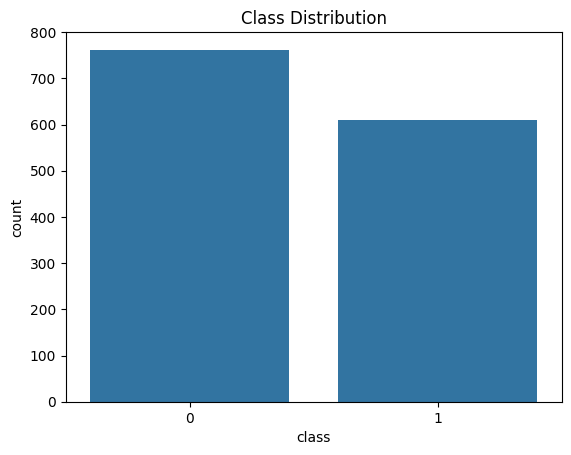

In [ ]:
sns.countplot(x='class', data=df)
plt.title("Class Distribution")
plt.show()

## **Preprocessing(Normalization)**



In [ ]:
X = df.drop('class', axis=1)
y = df['class']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## **Visualization (after preprocessing)**

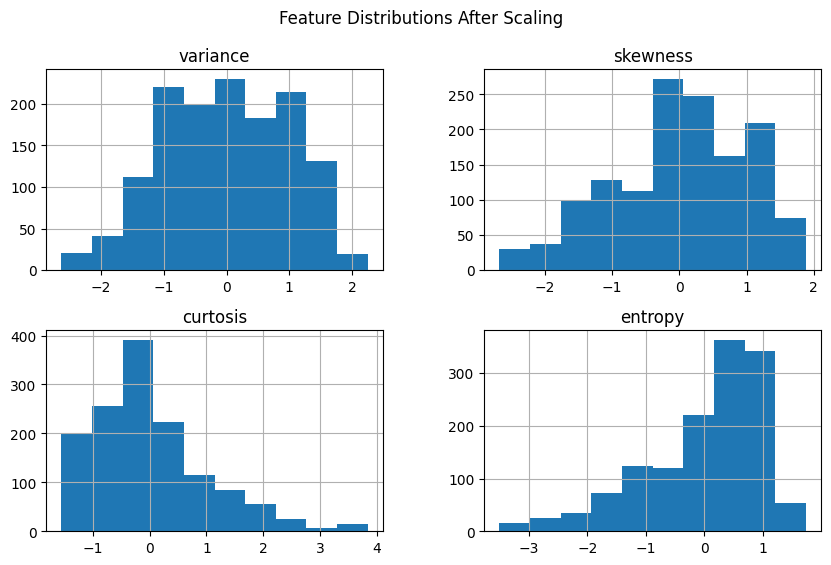

In [ ]:
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled_df.hist(figsize=(10,6))
plt.suptitle("Feature Distributions After Scaling")
plt.show()

## **Train/Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

## **Model Implementation**

## Logistic Regression
A linear approach to binary classification

In [ ]:
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

In [ ]:
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-score:", f1_score(y_test, y_pred_log))

Logistic Regression Results
Accuracy: 0.9709090909090909
Precision: 0.9384615384615385
Recall: 1.0
F1-score: 0.9682539682539683


## Confusion Matrix

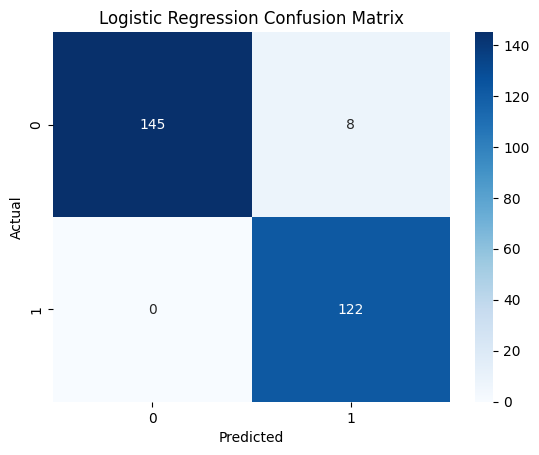

In [ ]:
cm_log = confusion_matrix(y_test, y_pred_log)

sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Decision Tree
A non-linear tree-based approach to capture complex patterns

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
print("Decision Tree Results")
print("Accuracy: ", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:   ", recall_score(y_test, y_pred_dt))
print("F1-score: ", f1_score(y_test, y_pred_dt))

Decision Tree Results
Accuracy:  0.9927272727272727
Precision: 0.9838709677419355
Recall:    1.0
F1-score:  0.991869918699187


## Confusion Matrix

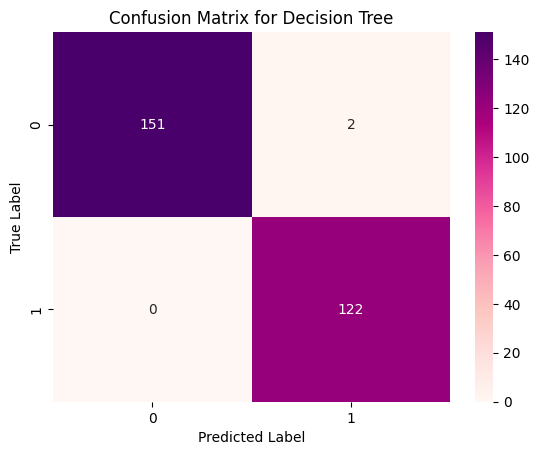

In [ ]:
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='RdPu')

plt.title('Confusion Matrix for Decision Tree')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## **Performance Evaluation**

In [ ]:
comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_log)
    ],
    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt)
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.970909,0.992727
1,Precision,0.938462,0.983871
2,Recall,1.000000,1.000000
3,F1-Score,0.968254,0.991870


## **Conclusion**

Our analysis demonstrates that Machine Learning can detect forged banknotes with high precision. Both models achieved excellent accuracy, but the **Decision Tree** showed superior performance in identifying specific non-linear boundaries within the wavelet data.
